In [1]:
import sys
sys.path.append("..")
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from src.features import group_labels, add_features

Path("../models").mkdir(exist_ok=True)
Path("../results/figures").mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/clean_sampled.parquet")
df = group_labels(df)
df = add_features(df)

num = df.select_dtypes("number")
print("Infinite:", np.isinf(num).sum().sum(), "| Missing:", df.isna().sum().sum())
print(df["Label"].value_counts())
print("Shape:", df.shape)

Infinite: 0 | Missing: 0
Label
DoS            80899
Benign         60000
DDoS           60000
Port Scan      60000
Brute Force     9150
Web Attack      2143
Bot             1948
Other             47
Name: count, dtype: int64
Shape: (274187, 85)


In [3]:
train, test = train_test_split(
    df, test_size=0.2, stratify=df["Label"], random_state=42
)
print("Train:", train.shape, "| Test:", test.shape)

props = pd.DataFrame({
    "train_%": train["Label"].value_counts(normalize=True) * 100,
    "test_%": test["Label"].value_counts(normalize=True) * 100,
    "test_rows": test["Label"].value_counts(),
}).round(2)
print(props)

Train: (219349, 85) | Test: (54838, 85)
             train_%  test_%  test_rows
Label                                  
Benign         21.88   21.88      12000
Bot             0.71    0.71        390
Brute Force     3.34    3.34       1830
DDoS           21.88   21.88      12000
DoS            29.51   29.51      16180
Other           0.02    0.02          9
Port Scan      21.88   21.88      12000
Web Attack      0.78    0.78        429


In [4]:
feature_cols = [c for c in train.columns if c not in ("Label", "Label_fine")]
X_train = train[feature_cols]

# 1) constant columns
constant = [c for c in feature_cols if X_train[c].nunique() <= 1]
print("Constant columns:", constant)
keep = [c for c in feature_cols if c not in constant]

# 2) highly correlated columns (> 0.95)
corr = X_train[keep].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
correlated = [c for c in upper.columns if (upper[c] > 0.95).any()]
final_features = [c for c in keep if c not in correlated]

print(f"Started with {len(feature_cols)} features")
print(f"Dropped {len(constant)} constant and {len(correlated)} highly correlated")
print(f"Kept {len(final_features)} features")
print("Engineered features that survived:",
      [c for c in ["total_packets", "total_bytes", "fwd_bwd_packet_ratio",
                   "fwd_bwd_bytes_ratio", "bytes_per_packet"] if c in final_features])

Constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Started with 83 features
Dropped 8 constant and 30 highly correlated
Kept 45 features
Engineered features that survived: ['fwd_bwd_packet_ratio', 'fwd_bwd_bytes_ratio']


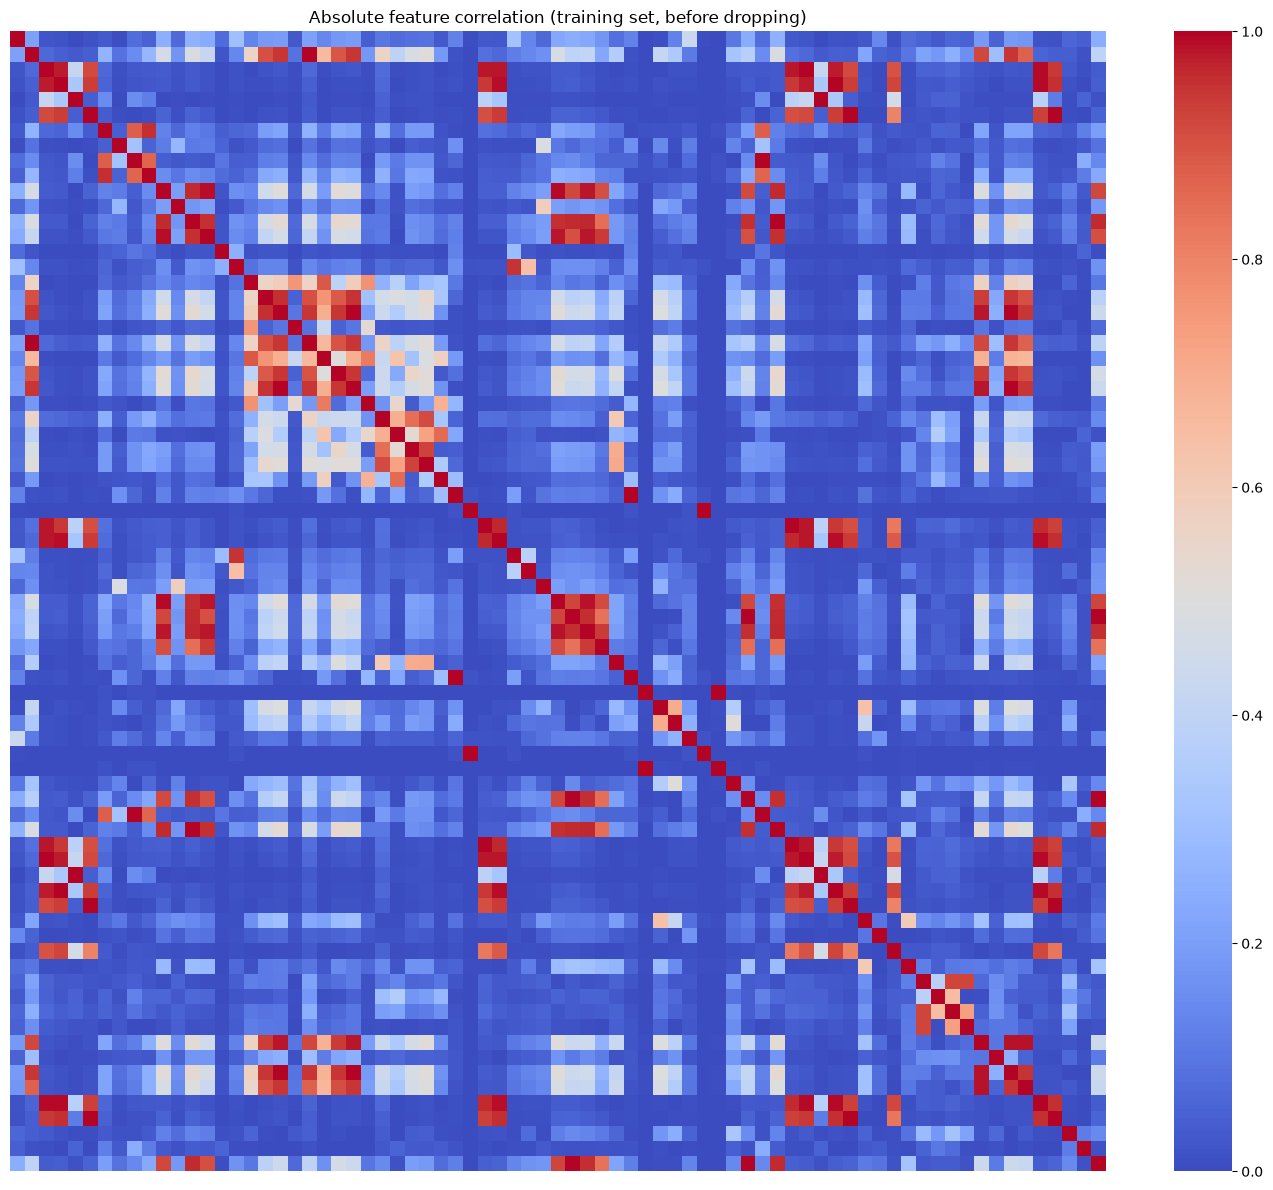

In [5]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", vmin=0, vmax=1, xticklabels=False, yticklabels=False)
plt.title("Absolute feature correlation (training set, before dropping)")
plt.tight_layout()
plt.savefig("../results/figures/correlation_heatmap.png", dpi=150)
plt.show()

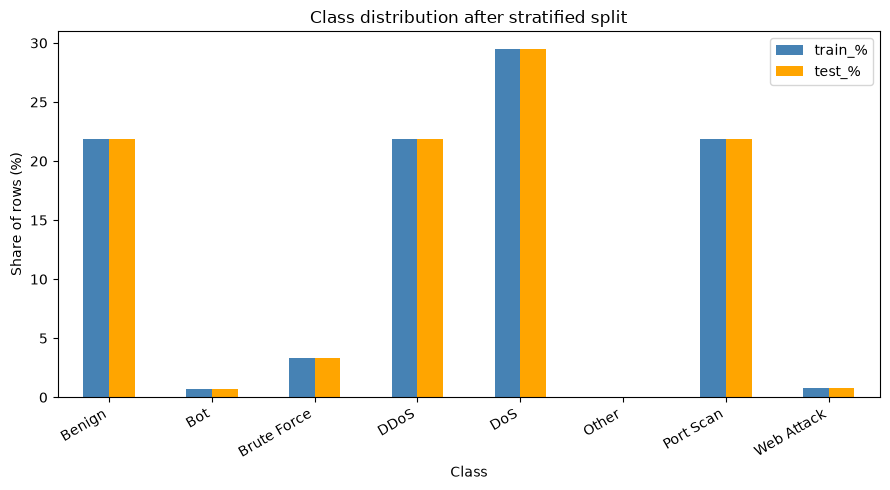

In [6]:
props[["train_%", "test_%"]].plot(kind="bar", figsize=(9, 5), color=["steelblue", "orange"])
plt.ylabel("Share of rows (%)")
plt.xlabel("Class")
plt.title("Class distribution after stratified split")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../results/figures/split_class_distribution.png", dpi=150)
plt.show()

In [7]:
scaler = StandardScaler().fit(train[final_features])    # learns only from training data

cols = final_features + ["Label", "Label_fine"]
train[cols].to_parquet("../data/processed/train.parquet")
test[cols].to_parquet("../data/processed/test.parquet")

joblib.dump(scaler, "../models/scaler.joblib")
joblib.dump(final_features, "../models/feature_columns.joblib")
json.dump(sorted(df["Label"].unique().tolist()), open("../models/classes.json", "w"))
print("Saved train, test, scaler, feature list, class list")

Saved train, test, scaler, feature list, class list
